# 확률·통계: 손실 함수의 수학적 기반

> A2-1 · 확률분포 시각화, Softmax, 그리고 **MSE = 정규분포 MLE**, **Cross-Entropy = 베르누이/카테고리 MLE**

손실 함수는 임의로 고른 거리 척도가 아니라, "데이터가 어떤 확률분포에서 나왔다"는 **가정의 음의 로그 가능도(NLL)** 이다.

| 데이터에 대한 가정 | 음의 로그 가능도 | 손실 함수 |
|---|---|---|
| $y = f(x) + \varepsilon,\ \varepsilon \sim \mathcal N(0, \sigma^2)$ (연속값 + 가우시안 노이즈) | $\tfrac n2\ln(2\pi\sigma^2) + \tfrac{n}{2\sigma^2}\,\mathrm{MSE}$ | **MSE** |
| $y \in \{0,1\}$, $y \sim \mathrm{Bernoulli}(\hat y)$ | $n\cdot\mathrm{BCE}$ | **Binary Cross-Entropy** |
| $y \in \{1,\dots,C\}$, $y \sim \mathrm{Categorical}(\mathrm{softmax}(z))$ | $n\cdot\mathrm{CE}$ | **Cross-Entropy** |

1장에서 분포를 그려 보고, 2장에서 Softmax를 구현한 뒤, 3~4장에서 위 표를 수식으로 유도하고 수치로 확인한다.

## 0. 준비

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve().parent  # notebooks/ 의 상위 폴더
sys.path.insert(0, str(PROJECT_ROOT))
from src.calculus import numerical_gradient  # 중심차분 수치 기울기 (4장 검증에 사용)

OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
SEED = 42
np.random.seed(SEED)
np.set_printoptions(precision=4, suppress=True)
sns.set_theme(style="whitegrid")

## 1. 확률 분포 시각화

### 1.1 정규분포 PDF — $\mathcal N(0, 1)$ 과 $\mathcal N(2, 0.5)$

$$
p(x) = \frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\Big(-\frac{(x-\mu)^2}{2\sigma^2}\Big)
$$

미션의 노이즈 표기 $\varepsilon \sim N(0, \sigma^2)$ 와 같게 $\mathcal N(\mu, \sigma^2)$ 의 두 번째 값을 **분산**으로 읽는다. 따라서 $\mathcal N(2, 0.5)$ 는 평균 2, 분산 0.5 (표준편차 $\approx 0.707$) 이다.

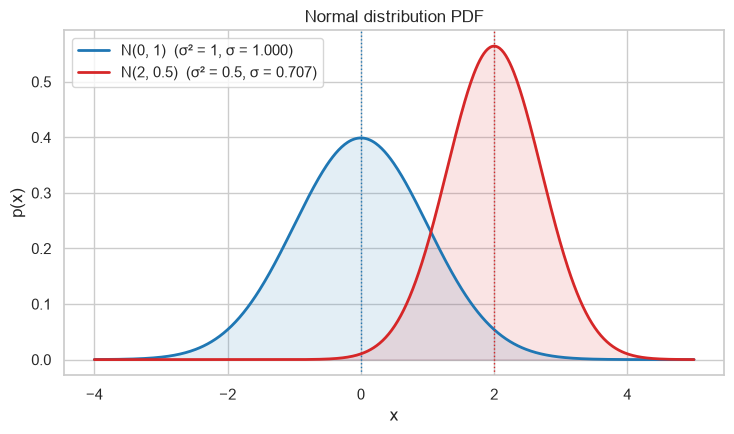

N(0, 1): 최댓값 0.3989, 구간 [-4, 5] 적분 = 0.999968
N(2, 0.5): 최댓값 0.5642, 구간 [-4, 5] 적분 = 0.999989


In [2]:
def normal_pdf(x, mu=0.0, var=1.0):
    """N(mu, var) 의 확률밀도함수. p(x) = exp(-(x-mu)^2 / (2 var)) / sqrt(2 pi var)"""
    return np.exp(-((x - mu) ** 2) / (2.0 * var)) / np.sqrt(2.0 * np.pi * var)


x = np.linspace(-4, 5, 600)
specs = [(0.0, 1.0, "#1f77b4"), (2.0, 0.5, "#d62728")]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for mu, var, color in specs:
    ax.plot(
        x,
        normal_pdf(x, mu, var),
        color=color,
        lw=2,
        label=f"N({mu:g}, {var:g})  (σ² = {var:g}, σ = {np.sqrt(var):.3f})",
    )
    ax.fill_between(x, normal_pdf(x, mu, var), color=color, alpha=0.12)
    ax.axvline(mu, color=color, ls=":", lw=1)
ax.set_xlabel("x")
ax.set_ylabel("p(x)")
ax.set_title("Normal distribution PDF")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "normal_pdf.png", dpi=150, bbox_inches="tight")
plt.show()

for mu, var, _ in specs:
    area = np.trapezoid(normal_pdf(x, mu, var), x)  # PDF 전체 적분은 1 이어야 한다
    print(
        f"N({mu:g}, {var:g}): 최댓값 {normal_pdf(mu, mu, var):.4f}, 구간 [-4, 5] 적분 = {area:.6f}"
    )
    assert abs(area - 1.0) < 1e-4

분산이 작을수록 곡선이 좁고 높다. 면적(적분)은 모두 1이므로, 한쪽이 좁아지면 그만큼 높아져야 한다. $\mathcal N(2, 0.5)$ 의 최댓값 $1/\sqrt{2\pi\cdot0.5} = 0.5642$ 는 $\mathcal N(0,1)$ 의 $0.3989$ 보다 높다.

### 1.2 베르누이 PMF — $B(0.3)$ 과 $B(0.7)$

$$
P(Y=k) = p^{k}(1-p)^{1-k}, \qquad k \in \{0, 1\}
$$

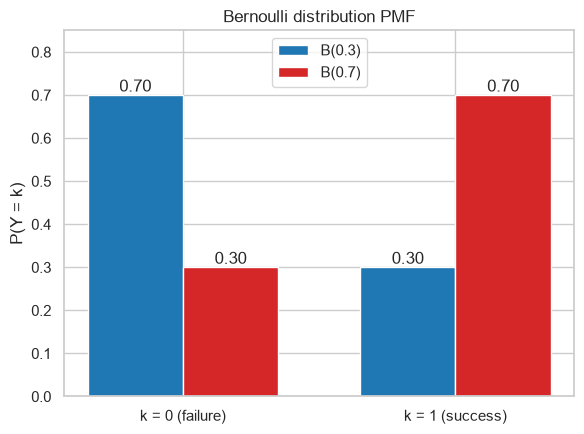

B(0.3): [0.7 0.3]  B(0.7): [0.3 0.7]  (각각 합 = 1)


In [3]:
def bernoulli_pmf(k, p):
    """Bernoulli(p) 의 확률질량함수. P(Y=k) = p^k (1-p)^(1-k), k ∈ {0, 1}"""
    return p**k * (1.0 - p) ** (1 - k)


ks = np.array([0, 1])
width = 0.35

fig, ax = plt.subplots(figsize=(6, 4.5))
for offset, p, color in ((-width / 2, 0.3, "#1f77b4"), (width / 2, 0.7, "#d62728")):
    pmf = bernoulli_pmf(ks, p)
    bars = ax.bar(ks + offset, pmf, width, color=color, label=f"B({p})")
    ax.bar_label(bars, fmt="%.2f")
    assert abs(pmf.sum() - 1.0) < 1e-12
ax.set_xticks(ks, ["k = 0 (failure)", "k = 1 (success)"])
ax.set_ylim(0, 0.85)
ax.set_ylabel("P(Y = k)")
ax.set_title("Bernoulli distribution PMF")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "bernoulli_pmf.png", dpi=150, bbox_inches="tight")
plt.show()
print(
    "B(0.3):",
    bernoulli_pmf(ks, 0.3),
    " B(0.7):",
    bernoulli_pmf(ks, 0.7),
    " (각각 합 = 1)",
)

두 분포는 $k=0$ 과 $k=1$ 의 값이 서로 바뀐 거울상이다 ($p \leftrightarrow 1-p$). $p$ 가 클수록 성공(1)이 더 자주 나온다.

## 2. Softmax

점수(logit) 벡터 $z \in \mathbb R^C$ 를 확률 벡터로 바꾼다.

$$
\operatorname{softmax}(z)_i = \frac{e^{z_i}}{\sum_{j} e^{z_j}}
$$

분자와 분모에 같은 상수 $e^{-c}$ 를 곱해도 값이 변하지 않으므로, $c = \max_j z_j$ 를 빼서 $e^{z}$ 가 넘치는(overflow) 것을 막는다.

In [4]:
def softmax(z, axis=-1):
    """softmax(z)_i = exp(z_i) / Σ_j exp(z_j). 최댓값을 먼저 빼서 overflow 를 막는다 (결과는 같다)."""
    shifted = z - np.max(z, axis=axis, keepdims=True)
    e = np.exp(shifted)
    return e / np.sum(e, axis=axis, keepdims=True)


def softmax_naive(z):
    """최댓값을 빼지 않는 순진한 구현 (비교용)."""
    e = np.exp(z)
    return e / e.sum()


z = np.array([2.0, 1.0, 0.1])
p = softmax(z)
print("softmax([2, 1, 0.1]) =", p, " 합 =", p.sum())

big = np.array([1000.0, 1001.0, 1002.0])
with np.errstate(over="ignore", invalid="ignore"):
    print("\n순진한 구현 [1000, 1001, 1002]:", softmax_naive(big))
print("안정한 구현 [1000, 1001, 1002]:", softmax(big))

# 합이 1 인지: 임의의 logit 1000개 × 클래스 10개 (+ 매우 큰/작은 값)
np.random.seed(SEED)
logits = np.random.normal(0.0, 5.0, size=(1000, 10))
logits[0] = [1000, 1001, 1002, -1000, 0, 0, 0, 0, 0, 0]
sums = softmax(logits).sum(axis=1)
max_gap = np.max(np.abs(sums - 1.0))
print(f"\n1000개 벡터의 합과 1.0 의 최대 차이 = {max_gap:.2e}")
assert max_gap < 1e-6
assert np.all(softmax(logits) >= 0)

softmax([2, 1, 0.1]) = [0.659  0.2424 0.0986]  합 = 1.0

순진한 구현 [1000, 1001, 1002]: [nan nan nan]
안정한 구현 [1000, 1001, 1002]: [0.09   0.2447 0.6652]

1000개 벡터의 합과 1.0 의 최대 차이 = 4.44e-16


## 3. MSE 최소화 = 정규분포 가정 하의 MLE

### 3.1 유도

모델 $y_i = f(x_i;\theta) + \varepsilon_i$, 노이즈 $\varepsilon_i \sim \mathcal N(0,\sigma^2)$ 가 서로 독립이라고 가정하면 $y_i \mid x_i \sim \mathcal N\big(f(x_i;\theta),\ \sigma^2\big)$ 이므로

$$
p(y_i \mid x_i;\theta) = \frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\Big(-\frac{(y_i - f(x_i;\theta))^2}{2\sigma^2}\Big)
$$

데이터 $n$ 개의 **우도**는 독립이므로 곱이다. 곱은 다루기 어렵고 $\log$ 는 증가 함수라 최대 위치가 같으므로 로그를 씌운다.

$$
\hat\theta_{\mathrm{MLE}} = \arg\max_\theta \prod_{i=1}^{n} p(y_i \mid x_i;\theta)
= \arg\max_\theta \sum_{i=1}^{n} \log p(y_i \mid x_i;\theta)
$$

$$
\sum_{i=1}^{n} \log p(y_i \mid x_i;\theta)
= \sum_{i=1}^{n}\Big[-\frac{(y_i - f(x_i;\theta))^2}{2\sigma^2} - \tfrac12\log(2\pi\sigma^2)\Big]
= -\frac{1}{2\sigma^2}\sum_{i=1}^{n}\big(y_i - f(x_i;\theta)\big)^2 \;-\; \frac n2\log(2\pi\sigma^2)
$$

둘째 항은 $\theta$ 와 무관한 상수이고, $\dfrac{1}{2\sigma^2} > 0$ 은 양의 상수배라서 최대/최소 위치를 바꾸지 않는다. 최대화를 부호를 바꿔 최소화로 쓰면

$$
\hat\theta_{\mathrm{MLE}} = \arg\min_\theta \sum_{i=1}^{n}\big(y_i - f(x_i;\theta)\big)^2 = \arg\min_\theta \underbrace{\frac1n\sum_{i=1}^{n}\big(y_i - f(x_i;\theta)\big)^2}_{\mathrm{MSE}}
$$

즉 NLL $= \dfrac n2\ln(2\pi\sigma^2) + \dfrac{n}{2\sigma^2}\,\mathrm{MSE}$ 로, **NLL 은 MSE 의 증가하는 1차 함수**이므로 두 최소점이 같다.

**덤: 분산의 MLE.** $\sigma^2$ 도 모르면 $\dfrac{\partial}{\partial\sigma^2}$ NLL $= \dfrac{n}{2\sigma^2} - \dfrac{n\,\mathrm{MSE}}{2\sigma^4} = 0$ 에서 $\hat\sigma^2 = \mathrm{MSE}$ 이다.

### 3.2 수치 확인

$y = 2x + \varepsilon$ ($\varepsilon \sim \mathcal N(0, 1)$, $n=50$) 에서 기울기 $w$ 를 바꿔 가며 (a) PDF 로 직접 계산한 NLL 과 (b) MSE 를 비교한다.

NLL 과 n/2·ln(2πσ²) + n·MSE/(2σ²) 의 최대 차이 = 1.14e-13
argmin MSE = 1.96,  argmin NLL = 1.96,  최소제곱 해 w* = 1.9644
σ² 의 MLE = 최소 MSE = 0.8233 (참값 1.0)


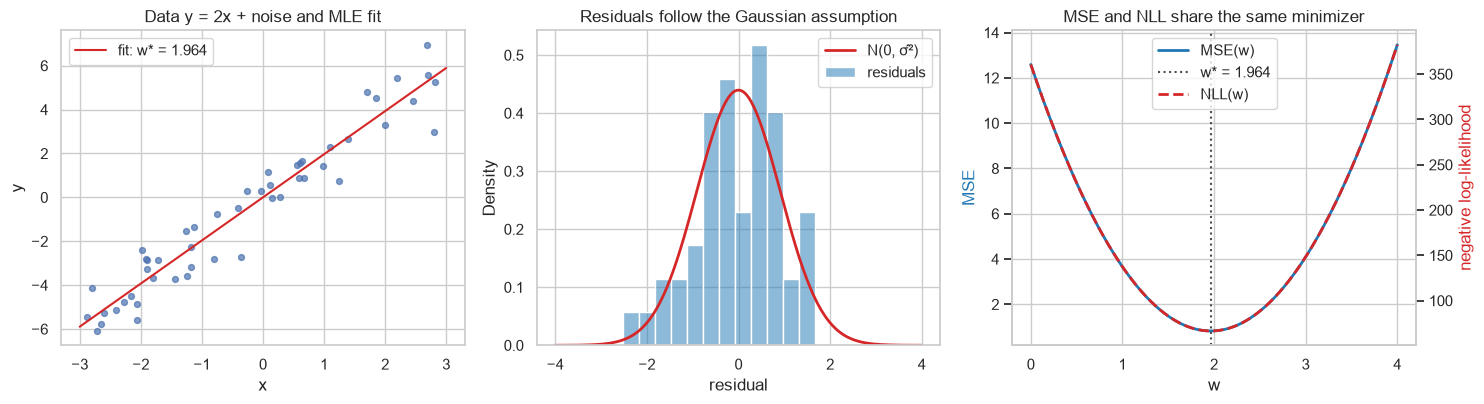

In [5]:
np.random.seed(SEED)
n, w_true, sigma2 = 50, 2.0, 1.0
x_data = np.random.uniform(-3, 3, n)
y_data = w_true * x_data + np.random.normal(0.0, np.sqrt(sigma2), n)

w_grid = np.linspace(0.0, 4.0, 401)
mse = np.array([np.mean((y_data - w * x_data) ** 2) for w in w_grid])
# PDF 로 직접 계산한 음의 로그 가능도 (위 유도 결과를 쓰지 않는다)
nll = np.array(
    [-np.sum(np.log(normal_pdf(y_data, w * x_data, sigma2))) for w in w_grid]
)

# (1) NLL = n/2 ln(2πσ²) + n·MSE / (2σ²) 항등식
predicted = n / 2 * np.log(2 * np.pi * sigma2) + n * mse / (2 * sigma2)
print(
    f"NLL 과 n/2·ln(2πσ²) + n·MSE/(2σ²) 의 최대 차이 = {np.max(np.abs(nll - predicted)):.2e}"
)
assert np.allclose(nll, predicted)

# (2) 두 곡선의 최소점이 같다 = 해석적 최소제곱 해 w* = Σxy / Σx²
w_star = np.sum(x_data * y_data) / np.sum(x_data**2)
print(
    f"argmin MSE = {w_grid[np.argmin(mse)]:.2f},  argmin NLL = {w_grid[np.argmin(nll)]:.2f},  최소제곱 해 w* = {w_star:.4f}"
)
assert np.argmin(mse) == np.argmin(nll)
assert abs(w_grid[np.argmin(mse)] - w_star) <= 0.005 + 1e-12

# (3) σ² 의 MLE 는 최소 MSE
resid = y_data - w_star * x_data
print(f"σ² 의 MLE = 최소 MSE = {np.mean(resid**2):.4f} (참값 {sigma2})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].scatter(x_data, y_data, s=18, alpha=0.7)
axes[0].plot(
    [-3, 3], [-3 * w_star, 3 * w_star], color="#d62728", label=f"fit: w* = {w_star:.3f}"
)
axes[0].set_title("Data y = 2x + noise and MLE fit")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].legend()

sns.histplot(
    resid,
    stat="density",
    bins=12,
    color="#1f77b4",
    alpha=0.5,
    ax=axes[1],
    label="residuals",
)
grid = np.linspace(-4, 4, 300)
axes[1].plot(
    grid,
    normal_pdf(grid, 0.0, np.mean(resid**2)),
    color="#d62728",
    lw=2,
    label="N(0, σ̂²)",
)
axes[1].set_title("Residuals follow the Gaussian assumption")
axes[1].set_xlabel("residual")
axes[1].legend()

ax_l = axes[2]
ax_r = ax_l.twinx()
ax_l.plot(w_grid, mse, color="#1f77b4", lw=2, label="MSE(w)")
ax_r.plot(w_grid, nll, color="#d62728", lw=2, ls="--", label="NLL(w)")
ax_l.axvline(w_star, color="0.3", ls=":", label=f"w* = {w_star:.3f}")
ax_l.set_xlabel("w")
ax_l.set_ylabel("MSE", color="#1f77b4")
ax_r.set_ylabel("negative log-likelihood", color="#d62728")
ax_r.grid(False)
ax_l.set_title("MSE and NLL share the same minimizer")
lines = ax_l.get_lines() + ax_r.get_lines()
ax_l.legend(lines, [ln.get_label() for ln in lines], loc="upper center")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "mse_mle.png", dpi=150, bbox_inches="tight")
plt.show()

**해석.** NLL 곡선과 MSE 곡선은 모양이 같고 (한 곡선이 다른 곡선의 1차 함수), 최소점이 같다. 그래서 정규분포 노이즈를 가정한 최대우도 추정이 곧 MSE 최소화(최소제곱법)이다. 이 가정이 틀리면(예: 이상치가 많은 두꺼운 꼬리 분포) MSE 는 더 이상 최적의 선택이 아니다.

## 4. Cross-Entropy 최소화 = 베르누이/카테고리 가정 하의 MLE

### 4.1 베르누이 → Binary Cross-Entropy

$y_i \in \{0,1\}$ 이고 모델이 $\hat y_i = P(y_i = 1 \mid x_i;\theta)$ (예: $\hat y_i = \sigma(z_i)$) 를 낸다면 $y_i \mid x_i \sim \mathrm{Bernoulli}(\hat y_i)$ 이므로

$$
p(y_i \mid x_i;\theta) = \hat y_i^{\,y_i}\,(1-\hat y_i)^{1-y_i}
$$

$$
\hat\theta_{\mathrm{MLE}} = \arg\max_\theta \sum_{i=1}^{n}\big[\,y_i\log\hat y_i + (1-y_i)\log(1-\hat y_i)\,\big]
= \arg\min_\theta \underbrace{-\frac1n\sum_{i=1}^{n}\big[\,y_i\log\hat y_i + (1-y_i)\log(1-\hat y_i)\,\big]}_{\mathrm{BCE}}
$$

NLL $= n\cdot\mathrm{BCE}$ 이다. 모델이 데이터와 무관한 상수 $\hat y = p$ 하나뿐이면, $\dfrac{d}{dp}\sum_i[\,y_i\log p + (1-y_i)\log(1-p)\,] = \dfrac{\sum y_i}{p} - \dfrac{n - \sum y_i}{1-p} = 0$ 에서 $\hat p = \dfrac1n\sum y_i$, 즉 **표본 비율**이다.

### 4.2 카테고리 → Cross-Entropy

$C$ 개 클래스에서 모델이 $q_i = \operatorname{softmax}(z_i)$ 를 내고, 정답을 원-핫 $t_i$ 로 쓰면 $p(y_i \mid x_i;\theta) = \prod_c q_{ic}^{\,t_{ic}} = q_{i,y_i}$ 이다.

$$
\hat\theta_{\mathrm{MLE}} = \arg\max_\theta \sum_{i=1}^{n}\sum_{c=1}^{C} t_{ic}\log q_{ic}
= \arg\min_\theta \underbrace{-\frac1n\sum_{i=1}^{n}\sum_{c=1}^{C} t_{ic}\log q_{ic}}_{\mathrm{CE}}
$$

$C=2$ 이면 BCE 와 같다. 모델이 상수 확률 $q$ 하나뿐이면 $\sum_c n_c\log q_c$ 를 $\sum_c q_c = 1$ 조건에서 최대화한다 ($n_c$ = 클래스 $c$ 의 개수). 라그랑주 승수법으로 $\dfrac{n_c}{q_c} = \lambda$ 이고 합이 1이어야 하므로 $q_c = n_c/n$, 즉 **클래스 빈도**가 MLE 이다.

### 4.3 Softmax + CE 의 기울기

$\mathrm{CE}$ 를 logit $z$ 로 미분하면 (Sigmoid + BCE 의 $\hat y - y$ 와 같은 꼴로) 깔끔하게 정리된다.

$$
\frac{\partial\,\mathrm{CE}}{\partial z_{ic}} = \frac{1}{n}\big(q_{ic} - t_{ic}\big)
$$

### 4.4 수치 확인

[베르누이] NLL 과 n·BCE 의 최대 차이 = 2.84e-14
[베르누이] argmin BCE = 0.340,  표본 비율 = 0.340  (참값 0.3)

[카테고리] CE = 1.372336,  NLL(정답 확률) = 1.372336
[카테고리] ∂CE/∂z = (q - t)/n  vs 중심차분 최대 차이 = 2.39e-11
[카테고리] 학습된 softmax = [0.51 0.28 0.21],  클래스 빈도 = [0.51 0.28 0.21]


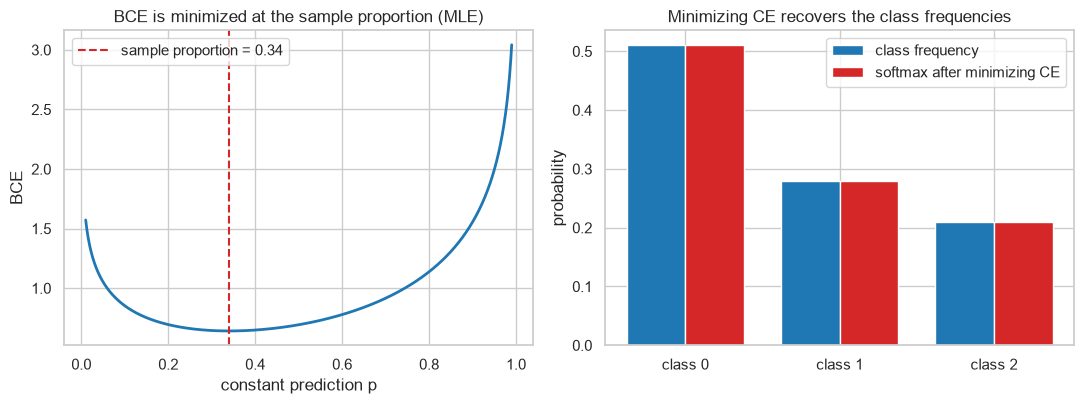

In [6]:
# (1) 베르누이: NLL(PMF 곱) = n · BCE, 최소점 = 표본 비율
np.random.seed(SEED)
n_b = 100
y_b = (np.random.uniform(size=n_b) < 0.3).astype(float)  # B(0.3) 에서 뽑은 데이터
p_grid = np.linspace(0.01, 0.99, 981)


def bce_const(p, y):
    """모든 샘플에 같은 확률 p 를 내는 모델의 BCE."""
    return -np.mean(y * np.log(p) + (1.0 - y) * np.log(1.0 - p))


bce_curve = np.array([bce_const(p, y_b) for p in p_grid])
nll_curve = np.array(
    [-np.sum(np.log(bernoulli_pmf(y_b, p))) for p in p_grid]
)  # PMF 로 직접 계산
assert np.allclose(nll_curve, n_b * bce_curve)
p_hat = y_b.mean()
print(
    f"[베르누이] NLL 과 n·BCE 의 최대 차이 = {np.max(np.abs(nll_curve - n_b * bce_curve)):.2e}"
)
print(
    f"[베르누이] argmin BCE = {p_grid[np.argmin(bce_curve)]:.3f},  표본 비율 = {p_hat:.3f}  (참값 0.3)"
)
assert abs(p_grid[np.argmin(bce_curve)] - p_hat) <= 0.0005 + 1e-12

# (2) 카테고리: 원-핫 CE = 정답 확률의 -log 평균 (NLL), 기울기 = (softmax - onehot) / n
np.random.seed(SEED)
n_c, C = 200, 3
true_freq = np.array([0.5, 0.3, 0.2])
labels = np.random.choice(C, size=n_c, p=true_freq)
onehot = np.eye(C)[labels]
logits_c = np.random.normal(size=(n_c, C))


def cross_entropy(logits, onehot):
    """CE = -(1/n) ΣΣ t_ic log q_ic,  q = softmax(logits)"""
    return -np.mean(np.sum(onehot * np.log(softmax(logits)), axis=1))


q = softmax(logits_c)
ce = cross_entropy(logits_c, onehot)
nll_c = -np.mean(
    np.log(q[np.arange(n_c), labels])
)  # 정답 클래스 확률만 뽑아 계산한 NLL
print(f"\n[카테고리] CE = {ce:.6f},  NLL(정답 확률) = {nll_c:.6f}")
assert np.isclose(ce, nll_c)

analytic = (q - onehot) / n_c
numeric = numerical_gradient(
    lambda t: cross_entropy(t.reshape(n_c, C), onehot), logits_c.ravel()
).reshape(n_c, C)
print(
    f"[카테고리] ∂CE/∂z = (q - t)/n  vs 중심차분 최대 차이 = {np.max(np.abs(analytic - numeric)):.2e}"
)
assert np.max(np.abs(analytic - numeric)) < 1e-8

# (3) 상수 모델의 CE 를 경사하강법으로 줄이면 softmax 출력이 클래스 빈도로 수렴한다
freq = onehot.mean(axis=0)
z_const = np.zeros(C)
for _ in range(3000):
    z_const -= 1.0 * (softmax(z_const) - freq)  # ∂CE/∂z = q - (빈도)
print(f"[카테고리] 학습된 softmax = {softmax(z_const)},  클래스 빈도 = {freq}")
assert np.allclose(softmax(z_const), freq, atol=1e-6)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(p_grid, bce_curve, color="#1f77b4", lw=2)
axes[0].axvline(
    p_hat, color="#d62728", ls="--", label=f"sample proportion = {p_hat:.2f}"
)
axes[0].set_xlabel("constant prediction p")
axes[0].set_ylabel("BCE")
axes[0].set_title("BCE is minimized at the sample proportion (MLE)")
axes[0].legend()

width = 0.38
idx = np.arange(C)
axes[1].bar(idx - width / 2, freq, width, color="#1f77b4", label="class frequency")
axes[1].bar(
    idx + width / 2,
    softmax(z_const),
    width,
    color="#d62728",
    label="softmax after minimizing CE",
)
axes[1].set_xticks(idx, [f"class {c}" for c in idx])
axes[1].set_ylabel("probability")
axes[1].set_title("Minimizing CE recovers the class frequencies")
axes[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "cross_entropy_mle.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. 정리

| | 정규분포 가정 | 베르누이/카테고리 가정 |
|---|---|---|
| 목표값 | 연속값 $y \in \mathbb R$ | 이산 라벨 $y \in \{0,1\}$ 또는 $\{1,\dots,C\}$ |
| 모델 출력 | 평균 $f(x;\theta)$ | 확률 $\hat y = \sigma(z)$ 또는 $\operatorname{softmax}(z)$ |
| NLL | $\frac n2\ln(2\pi\sigma^2) + \frac{n}{2\sigma^2}\mathrm{MSE}$ | $n\cdot\mathrm{BCE}$ / $n\cdot\mathrm{CE}$ |
| MLE (상수 모델) | 표본평균 | 표본 비율 / 클래스 빈도 |
| 출력층 기울기 | $\propto (\hat y - y)$ | $\hat y - y$ / $q - t$ |

- **MSE 와 CE 의 구분.** MSE 는 "오차가 정규분포를 따르는 연속값", CE 는 "라벨이 확률분포에서 뽑힌 이산값"이라는 서로 다른 가정에서 나온 손실이다. 분류에 MSE 를 쓰면 라벨이 가우시안 노이즈라는 맞지 않는 가정을 하는 셈이다.
- **같은 방법으로 보는 법.** 새로운 손실을 만나면 "이 손실은 어떤 분포의 NLL 인가?" 를 물어볼 수 있다 (예: 라플라스 분포 → MAE).
- 2장의 Softmax 합 검증(허용 $10^{-6}$)과 3~4장의 수치 확인(항등식, 최소점, 기울기)은 모두 `assert` 로 통과했다.